# Code Execution with Energy Profiling - For AMD GPU (and HIP code)

In [1]:
# Import modules
import shutil
import os
import lassi.code_manager
from lassi.amd_power import amd_report_gpu_memory, amd_idlepower
from lassi.gpu_detector import detect_gpu_vendors
from lassi.format_colors import color

In [2]:
# Auto-detect GPU vendor
vendors = detect_gpu_vendors()
if not vendors:
    print("❌ No GPUs detected! LASSI requires GPU hardware.")
    raise SystemExit("Pipeline stopped - no GPU hardware found")

gpu_vendor = vendors[0]['vendor']
gpu_count = vendors[0]['count']
print(f"🔍 Detected: {gpu_vendor.upper()} with {gpu_count} GPU(s)")

🔍 Detected: AMD with 2 GPU(s)


In [3]:
# Code to test and input parameters
folder = "source_codes/HeCBench/jacobi/"
code_filename = "jacobi-hip_main.cu"  # Using HIP version for AMD
exe_input_parameters = []  # jacobi doesn't need parameters

# Parameters - AMD Configuration
power_measure = True
source_language = "HIP"  # Changed from CUDA to HIP
target_language = "HIP"  # Changed from CUDA to HIP
build_script = False
code_compiler = "hipcc"  # Changed from nvcc to hipcc
code_compiler_kwds = "-std=c++14 -Wall -O3 --amdgpu-target=gfx908"  # AMD flags instead of NVIDIA
# --amdgpu-target=gfx908 for MI100  # --amdgpu-target=gfx90a for MI250X

print(f"\n--- AMD Energy Profiling Configuration ---")
print(f"GPU Vendor: {gpu_vendor.upper()}")
print(f"Source Language: {source_language}")
print(f"Compiler: {code_compiler}")
print(f"Compiler Flags: {code_compiler_kwds}")
print(f"Test File: {folder + code_filename}")


--- AMD Energy Profiling Configuration ---
GPU Vendor: AMD
Source Language: HIP
Compiler: hipcc
Compiler Flags: -std=c++14 -Wall -O3 --amdgpu-target=gfx908
Test File: source_codes/HeCBench/jacobi/jacobi-hip_main.cu


In [4]:
# Compile code (using original function - works for both NVIDIA and AMD)
print(f"\n--- Compilation Phase ---")
compile_result, execute_file = lassi.code_manager.compile_code(
    folder + code_filename,
    source_language,
    code_compiler,
    code_compiler_kwds
)

if compile_result != "":
    print(f"❌ Compilation failed: {compile_result}")
    raise SystemExit("Pipeline stopped - compilation failed")
else:
    print(f"✅ Compilation successful!")
    print(f"Executable: {execute_file}")


--- Compilation Phase ---
Compile command: ['hipcc', '-std=c++14', '-Wall', '-O3', '--amdgpu-target=gfx908', 'source_codes/HeCBench/jacobi/jacobi-hip_main.cu', '-o', 'source_codes/HeCBench/jacobi/jacobi-hip_main']

Compilation of code successful!

✅ Compilation successful!
Executable: source_codes/HeCBench/jacobi/jacobi-hip_main



--- AMD GPU System Check BEFORE Execution ---

----- AMD GPU Memory Status:


========================= ROCm System Management Interface =========================
=============================== Memory Usage (Bytes) ===============================
GPU[0]		: VRAM Total Memory (B): 34342961152
GPU[0]		: VRAM Total Used Memory (B): 6762496
GPU[1]		: VRAM Total Memory (B): 34342961152
GPU[1]		: VRAM Total Used Memory (B): 6762496
=============================== End of ROCm SMI Log ================================

----- AMD GPU State:


========================= ROCm System Management Interface =========================
=================================== Concise Info ===================================
GPU  Temp (DieEdge)  AvgPwr  SCLK    MCLK     Fan  Perf  PwrCap  VRAM%  GPU%  
0    23.0c           34.0W   300Mhz  1200Mhz  0%   auto  290.0W    0%   0%    
1    24.0c           34.0W   300Mhz  1200Mhz  0%   auto  290.0W    0%   0%    
=============================== End of ROCm SMI Log =

Waiting for the system to settle down for 5 seconds...: 100%|█| 5/5 [00:05<00:00


executable_file:  source_codes/HeCBench/jacobi/jacobi-hip_main
initial_dir:  /home/cc/lassi/LASSI-EE
directory_path:  source_codes/HeCBench/jacobi
executable:  jacobi-hip_main
Working directory: /home/cc/lassi/LASSI-EE/source_codes/HeCBench/jacobi
Execute command: ['./jacobi-hip_main']

running: executable -  jacobi-hip_main

----- < BEGIN: STANDARD OUTPUT FROM CODE EXECUTION > -----

Error after iteration 0 = 0.00781059
Error after iteration 1000 = 3.91151e-05
Error after iteration 2000 = 2.32109e-05
Error after iteration 3000 = 1.70863e-05
Error after iteration 4000 = 1.37387e-05
Error after iteration 5000 = 1.15946e-05
Error after iteration 6000 = 1.00892e-05
Average execution time per iteration: 0.0019535 (s)
PASS
Total elapsed time: 12.84 seconds

----- < END: Standard Output > -----

GPU power data has been written to HIP_HIP_gpu_net_power_results.csv


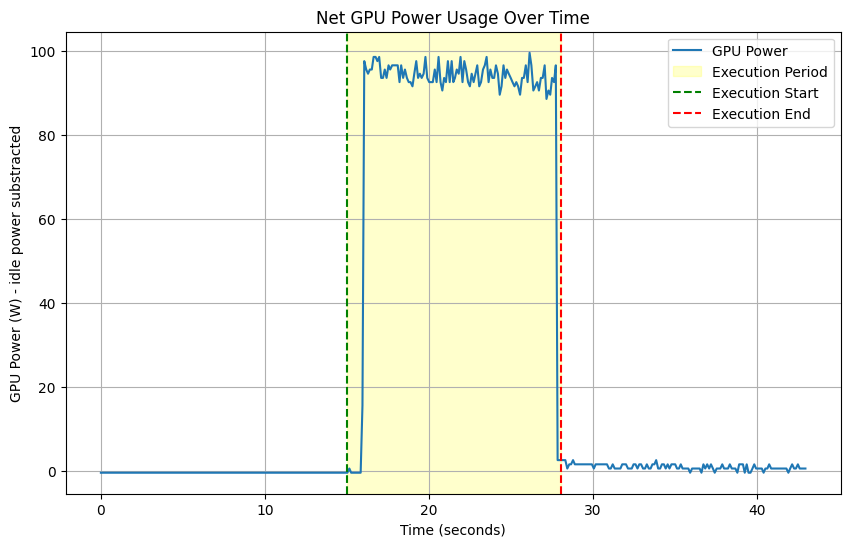

Start time: 15.001 -- End time: 28.083
Net (idle corrected) GPU energy consumption for HIP_HIP_gpu_net_power_results.csv:
  0.000310 kWh
  0.3099 Wh
  1115.75 J
Average GPU power: 85.48 W +/- 27.42 
 with sample standard deviation.
Net Energy During Exe Runtime:   1115.75 J
Code execution duration:  13.08 seconds
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!

----- >>> AMD GPU system check AFTER exe code...

----- AMD GPU Memory Status:


========================= ROCm System Management Interface =========================
=============================== Memory Usage (Bytes) ===============================
GPU[0]		: VRAM Total Memory (B): 34342961152
GPU[0]		: VRAM Total Used Memory (B): 6762496
GPU[1]		: VRAM Total Memory (B): 34342961152
GPU[1]		: VRAM Total Used Memory (B): 6762496
=============================== End of ROCm SMI Log ==============================

In [5]:
# Execute code with AMD Energy Profiling
print(f"\n--- AMD GPU System Check BEFORE Execution ---")
amd_report_gpu_memory()

print(f"\n--- Execution with Power Monitoring ---")
execute_result, exe_output, total_energy_joules, ave_power, std_power, duration, metrics_results_string = lassi.code_manager.execute_code_selectvendor(
    experiment_data_directory="./temp_amd_test",  # Temporary directory for test
    code_version=1,
    zero_shot=False,
    trial_number=1,
    directory="",
    executable_file=execute_file,
    exe_input_parameters=exe_input_parameters,
    power_measure=power_measure,
    code_source=source_language,
    target_lang=target_language,
    build_script=build_script,
    make_script=False,
    gpu_vendor="amd",  # Explicitly specify AMD
    wait=5
)

if execute_result != "0":
    print(f"❌ Execution failed: {execute_result}")
else:
    print(f"✅ Execution successful!")

print(f"\n--- AMD GPU System Check AFTER Execution ---")
amd_report_gpu_memory()

# Display results
print(f"\n--- AMD Energy Profiling Results ---")
print(f"Execution Duration: {color.BOLD}{duration:.2f} seconds{color.END}")
print(f"Total Energy Consumed: {color.BOLD}{total_energy_joules:.2f} J{color.END}")
print(f"Average GPU Power: {color.BOLD}{ave_power:.2f} W ± {std_power:.2f}{color.END}")

print(f"\n--- Program Output ---")
print(exe_output)

## Optional - Measure system idle power
Using same runtime as code execution above.


--- Optional: AMD Idle Power Measurement ---
Measuring AMD GPU idle power for same duration...
Duration for AMD idle time measurement: 12.27
GPU power data has been written to idle__gpu_net_power_results.csv


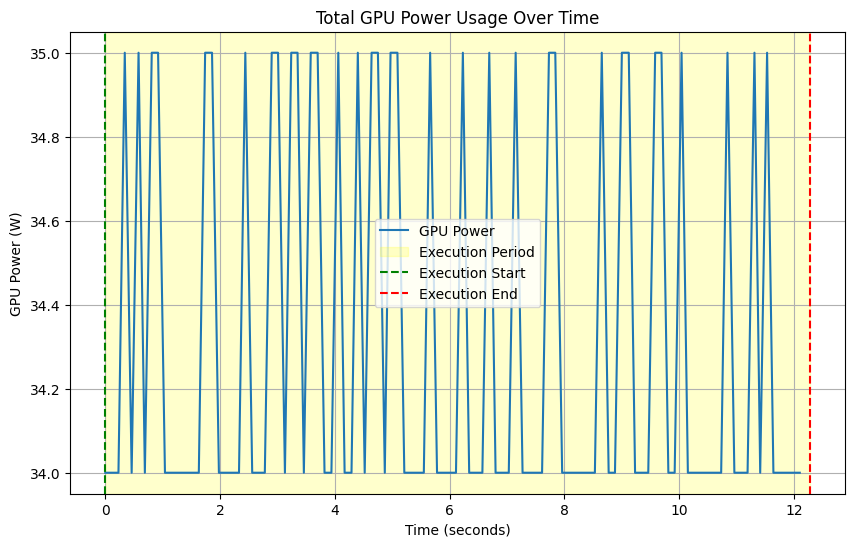

Start time: 0 -- End time: 12.274
Total GPU energy consumption for idle__gpu_net_power_results.csv:
  0.000116 kWh
  0.1165 Wh
  419.24 J
Average GPU power: 34.32 W +/- 0.47 
 with sample standard deviation.
Total Energy During Exe Runtime:   419.24 J
Code execution duration:  12.27 seconds
----------------------------------------------------------------------------------------------------------------------------------------

AMD Idle power measured values for same runtime as jacobi-hip_main.cu
Average GPU idle power: 34.32 W ± 0.47
Total Idle Energy During Code Runtime: 419.24 J

--- Net Energy Analysis (Code - Idle) ---
Net Energy Consumed: 688.48 J
Net Average Power: 55.49 W
Energy Efficiency: 56.10 J/s

✅ Cleaned up temporary test directory

🎉 AMD Energy Profiling Complete!


In [7]:
# Measure system idle power
print(f"\n--- Optional: AMD Idle Power Measurement ---")
print("Measuring AMD GPU idle power for same duration...")

idle_energy_joules, idle_ave_power, std_idle_ave_power = lassi.get_power.idlepower_selectvendor(
    experiment_data_directory="./temp_amd_test",
    trial_number=1,
    duration=duration,
    gpu_vendor="auto"
)

print(color.BOLD + color.BLUE + f"\nAMD Idle power measured values for same runtime as {code_filename}" + color.END)
print("Average GPU idle power: " + color.BOLD + f"{idle_ave_power:.2f} W ± {std_idle_ave_power:.2f}" + color.END)
print("Total Idle Energy During Code Runtime: " + color.BOLD + f"{idle_energy_joules:.2f} J" + color.END)

# Calculate net energy (code energy - idle energy)
net_energy = total_energy_joules - idle_energy_joules
net_power = ave_power - idle_ave_power

print(f"\n--- Net Energy Analysis (Code - Idle) ---")
print(f"Net Energy Consumed: {color.BOLD}{net_energy:.2f} J{color.END}")
print(f"Net Average Power: {color.BOLD}{net_power:.2f} W{color.END}")
print(f"Energy Efficiency: {color.BOLD}{net_energy/duration:.2f} J/s{color.END}")

# Cleanup temporary directory
if os.path.exists("./temp_amd_test"):
    shutil.rmtree("./temp_amd_test")
    print(f"\n✅ Cleaned up temporary test directory")

print(f"\n🎉 AMD Energy Profiling Complete!")